# 6장 1강: 전이학습의 기본 원리 — 실습문제

## 실습 목표

- Pretrained Model이 이미 어떤 데이터를 학습한 모델인지 설명합니다.
- 다른 건물에서 배운 특징을 새 건물에 재사용하는 Transfer Learning을 이해합니다.
- Feature Extraction에서 고정되는 부분과 학습되는 부분을 구분합니다.
- Fine-tuning에서 업데이트 범위가 어떻게 달라지는지 실제 파라미터로 확인합니다.

## 실습 구성

| 구분 | 문제 | 내용 |
|---|---|---|
| 실습 1 | 1-1 | 데이터 구분과 교육용 사전학습 모델 만들기 |
| 실습 1 | 1-2 | 사전학습 특징 추출과 출력층 학습 |
| 실습 2 | 2-1 | 작은 학습률로 미세조정하고 변경 부분 확인 |
| 실습 2 | 2-2 | 대상 건물에서 세 단계의 결과 해석 |
| 기초 과제 | 3-1 | 같은 조건에서 은닉층 고정 여부만 바꾸어 비교 |

**실습 2개 + 기초 과제 1개**입니다. 신경망의 순전파·역전파 학습 함수는 완성된 코드로 제공합니다. 함수를 새로 구현하거나 최적 성능을 찾는 과제가 아닙니다.

제공된 **6장 1강 목차: Pretrained Model과 Transfer Learning, Feature Extraction, Fine-tuning**을 기준으로 구성했습니다. 강의 본문은 별도로 제공되지 않았으므로 건물·기간·모델 크기·학습률은 원리를 확인하기 위한 실습 설정입니다.

## 이번 실습의 사전학습 모델

별도 사전학습 모델 파일이 제공되지 않았으므로 **1~4번 건물의 과거 자료로 작은 신경망을 먼저 학습**합니다. 학습이 끝난 그 상태를 5번 건물에 전달합니다. 외부에서 내려받는 대규모 범용 모델이 아니라, 노트북 안에서 직접 준비하는 **교육용 사전학습 모델**입니다.

전력소비량이라는 예측 대상은 같지만 건물과 데이터 분포가 달라집니다. 이런 관련 환경 사이에서도 학습한 특징을 재사용할 수 있습니다. 숫자가 들어 있는 임의의 가중치를 복사하는 것만으로 사전학습이 되는 것은 아닙니다.

## 데이터와 실행 방법

- Python, NumPy, pandas, Matplotlib을 사용합니다. GPU나 별도 딥러닝 프레임워크 설치는 필요하지 않습니다.
- **`전기사용량(2).csv`, `building_info(2).csv`**를 노트북과 같은 폴더에 두세요. 괄호가 없는 `전기사용량.csv`, `building_info.csv`도 읽을 수 있습니다.
- 전력 파일은 시간별 관측 204,000행·10열, 건물 파일은 100행·7열입니다. `건물번호`로 건물의 연면적·냉방면적 등을 연결합니다.
- 입력은 **기온, 습도, 시간, 요일, 연면적, 냉방면적**의 6개입니다. `hour`는 0~23, `weekday`는 월요일 0~일요일 6입니다. 시간·요일은 날짜에서 꺼내는 제공 전처리입니다.
- 정답은 **전력소비량(kWh)**입니다. 같은 시간의 기상 조건을 입력으로 사용하는 회귀 예제이며, 미래 기상을 모르는 상태에서 수행하는 다음 날 전력 예측 실험은 아닙니다.
- `건물유형`은 자료 확인에 사용하며 모델 입력에는 넣지 않습니다. 강수량·일조·일사 및 설비 용량은 이번 범위에서 제외합니다. 설비 열의 `-`를 임의로 0으로 바꾸어 사용하지 않습니다.

| 집합 | 건물 | 기간(양 끝 포함) | 행 수 | 역할 |
|---|---|---|---:|---|
| 사전학습 / Source | 1~4번 | 2022-06-01 00시~06-30 23시 | 2,880 | 특징을 먼저 학습 |
| 대상 학습 / Target Train | 5번 | 2022-07-01 00시~07-07 23시 | 168 | 새 건물에 맞게 업데이트 |
| 대상 검증 / Target Validation | 5번 | 2022-07-08 00시~07-14 23시 | 168 | 업데이트 없이 결과 확인 |

건물 번호와 기간은 빠른 실습을 위한 선택이며 최적 조합이라는 뜻은 아닙니다. 나머지 기록은 사용하지 않습니다. 시간 순서를 유지하며, 검증 기간의 정답을 사전학습이나 대상 학습에 사용하지 않습니다.

입력 결측값을 채울 중앙값과 입력·정답의 평균·표준편차는 **Source에서만** 구합니다. 이 기준을 세 집합에 동일하게 적용합니다. 제공 파일의 선택된 입력·기간에는 실제 결측값이 없습니다. 중앙값 처리는 같은 실행 흐름을 유지하기 위한 준비 코드입니다.

Loss는 앞 강의와 같은 MSE이며, 여기서는 **Source 기준으로 표준화된 전력소비량**에서 계산합니다. kWh 오차나 정확도(%)가 아닙니다. 예측값을 `표준화 예측값 × y_std + y_mean`으로 되돌리면 kWh로 읽을 수 있습니다.

## 먼저 알아둘 용어

| 용어 | 이번 실습에서의 의미 |
|---|---|
| Pretrained Model | 1~4번 건물로 학습을 마친 신경망 |
| Transfer Learning | 먼저 배운 은닉층의 특징을 5번 건물 학습에 재사용하는 과정 |
| Backbone / 특징 추출부 | 입력을 8개의 은닉층 출력으로 바꾸는 부분. W1과 b1을 사용 |
| Head / 출력층 | 8개의 특징을 전력소비량 예측 하나로 바꾸는 부분. W2와 b2를 사용 |
| Freeze / 동결 | 순전파 계산은 유지하면서 해당 가중치·편향을 업데이트하지 않는 것 |
| Feature Extraction | 사전학습 은닉층으로 특징을 만들고, 여기서는 그 은닉층을 고정한 채 새 출력층만 학습 |
| Fine-tuning | 이미 학습한 파라미터에서 출발하여 대상 데이터로 일부 또는 전체를 추가 조정. 여기서는 은닉층과 출력층 모두 조정 |

노트북 위에서부터 순서대로 실행하세요. 고정 난수를 사용하지만 환경에 따라 마지막 소수점 자릿수는 달라질 수 있습니다.

### 이 강의에서 ‘배운 것을 가져온다’는 뜻

신경망의 학습은 입력으로 예측값을 계산하고, 실제값과의 오차를 줄이도록 **가중치와 편향이라는 숫자를 수정하는 과정**입니다. 사전학습 모델은 어떤 데이터를 사용하여 이 과정을 이미 수행한 모델입니다. 모델 이름이나 구조가 같다는 이유만으로 사전학습 모델이 되는 것은 아닙니다.

이번에는 1~4번 건물의 자료가 비교적 많고, 5번 건물에 맞추는 데 사용하는 자료는 일주일치입니다. 관련 건물에서 먼저 익힌 계산 방법을 새 건물에서도 출발점으로 활용해 봅니다. 온도·습도·시간 같은 공통 입력과 전력 사용량 사이의 관계를 재사용할 가능성이 있기 때문입니다. 다만 건물별 운영 방식과 사용 규모가 다르므로, 가져온 계산 방법이 실제로 도움이 되는지는 대상 건물의 검증 결과로 확인해야 합니다.

‘지식 전달’은 사람이 정답을 설명해 주는 행위가 아니라 **학습된 파라미터 값을 가져오는 것**입니다. 모델의 구조와 입력 처리 방법도 그 값에 맞아야 합니다. 예를 들어 기온에 곱하도록 배운 가중치 자리에 갑자기 면적을 넣으면 같은 의미의 계산을 할 수 없습니다.

### 용어를 읽는 순서

| 용어 | 읽는 말과 쉬운 뜻 | 이번 실습 |
|---|---|---|
| Source | 소스. 먼저 배우는 쪽의 데이터 | 1~4번 건물의 6월 자료 |
| Target | 타깃. 배운 것을 적용·조정할 대상 쪽의 데이터 | 5번 건물의 7월 자료 |
| Pretrained | 프리트레인드. 미리 학습을 마친 상태 | `pretrained`의 가중치·편향 |
| Transfer Learning | 전이학습. 이전 학습 결과를 관련된 새 환경의 학습에 활용 | Source 은닉층을 Target에 재사용 |
| Feature | 특징. 입력을 표현하는 값 또는 모델이 만든 중간값 | 원래 입력 6개, 은닉 특징 8개를 구분 |
| Backbone | 백본. 특징을 만들어 주는 부분 | 은닉층 W1·b1 |
| Head | 헤드. 특징을 최종 예측으로 연결하는 부분 | 출력층 W2·b2 |
| Freeze | 프리즈·동결. 해당 파라미터를 바꾸지 않게 설정 | 은닉층은 계산하되 업데이트하지 않음 |
| Feature Extraction | 특징 추출. 학습된 층의 출력으로 새로운 표현 만들기 | H를 만들고, 동결한 은닉층 위의 새 출력층 학습 |
| Fine-tuning | 파인튜닝·미세조정. 학습된 값에서 출발하여 추가로 조정 | 은닉층의 동결을 풀고 대상 데이터로 추가 학습 |

Target이라는 말은 두 의미로 등장할 수 있습니다. **Target Train·Target Validation**은 ‘대상 건물의 데이터 집합’이고, 코드의 `target` 변수는 **정답 열 이름 `전력소비량(kWh)`**입니다. 대상 데이터 전체와 그 안의 정답 열을 구분하세요.

### 같은 모델을 단계별로 어떻게 사용하나요?

| 단계 | 처음 가져오는 것 | 이 단계에서 배우는 데이터 | 조정할 부분 |
|---|---|---|---|
| 사전학습 | 아직 학습하지 않은 초기값 | Source | 은닉층·출력층 모두 |
| 사전학습 모델 그대로 예측 | Source 학습 완료 모델 전체 | 추가 학습 없음 | 아무 파라미터도 바꾸지 않음 |
| Feature Extraction 방식 | Source 은닉층 + 새로 만든 출력층 | Target Train | 출력층만 |
| 이번 Fine-tuning | 바로 앞 Feature Extraction 학습 완료 모델 | Target Train | 은닉층·출력층 모두 |

Feature Extraction과 Fine-tuning은 이번 전이학습을 수행하는 방식·단계입니다. 서로 아무 관계 없는 별도 주제로 외우기보다 **어떤 값을 이어받았고, 그중 무엇을 고정하거나 조정하는가**를 중심으로 이해하세요. 이번에는 두 단계를 차례로 수행하지만 모든 전이학습에서 반드시 똑같은 순서를 써야 한다는 뜻은 아닙니다.

### 주제별 학습 위치

| 강의 주제 | 문제 | 확인할 핵심 |
|---|---|---|
| Pretrained Model·Transfer Learning | 실습 1-1 | 실제 사전학습 여부, Source·Target 구분, 전달되는 파라미터 |
| Feature Extraction | 실습 1-2 | 은닉 특징 H의 의미, 동결과 순전파, 출력층만 학습 |
| Fine-tuning | 실습 2-1 | 학습된 시작값, 동결 해제, 작은 학습률과 파라미터 변화 |
| 적용 결과 해석 | 실습 2-2 | 같은 검증 데이터로 비교, 표준화 MSE와 kWh 구분 |
| 기초 복습 | 과제 3-1 | 같은 출발점·학습률·횟수에서 동결 여부만 비교 |

과제는 제공 함수의 `True/False` 설정을 바꾸고 결과를 읽는 필수 수준입니다. 새로운 모델 구현이나 사전학습 모델을 외부에서 찾는 작업은 요구하지 않습니다.


## 공통 준비 코드 — 그대로 실행하세요

첫 셀은 파일 연결·기간 분리·전처리를 수행합니다. 두 번째 셀은 **입력 6개 → Tanh 은닉 뉴런 8개 → 선형 출력 1개**의 학습 함수를 제공합니다.

$$H=\tanh(XW_1+b_1),\qquad \hat y=HW_2+b_2$$

H는 은닉층이 만든 특징입니다. W1은 (6,8), b1은 (1,8), W2는 (8,1), b2는 (1,1) 모양입니다. 덧셈에서 편향은 각 행에 똑같이 더해집니다.

| 제공 함수 | 하는 일 |
|---|---|
| `init_model()` | 아직 학습하지 않은 초기 파라미터 생성 |
| `copy_model(params)` | 각 배열을 복사하여 원본을 보존 |
| `hidden_features(X, params)` | 은닉층 출력 H 계산 |
| `predict_scaled(X, params)` | 표준화된 전력소비량 예측 |
| `train_model(start, X, y, lr, epochs, train_backbone)` | start를 복사한 뒤 전달한 학습 데이터로만 업데이트 |
| `parameter_changes(before, after)` | 각 파라미터에서 바뀐 값의 최대 절댓값 확인 |
| `target_scores(models)` | 같은 대상 학습·검증 데이터에서 MSE 비교 |

`train_backbone=False`이면 W1·b1을 고정하고 W2·b2만 업데이트합니다. `True`이면 네 배열 모두 업데이트합니다. 두 경우 모두 은닉층을 거치는 순전파 계산은 수행합니다. 이 모델에는 Batch Normalization이나 Dropout이 없습니다.

학습 함수의 반환값은 `(학습 완료 파라미터, 학습 손실 기록)`입니다. 정해진 epoch를 수행하며 검증 결과로 중단 시점을 고르지 않습니다. 함수 내부는 제공 코드이므로 직접 유도하거나 외우지 않아도 됩니다.

### 수식을 말로 풀어 읽기

`H = tanh(X @ W1 + b1)`은 ① 입력 X에 가중치 W1을 곱하고 ② 편향 b1을 더하고 ③ Tanh 활성화 함수를 적용하여 은닉 특징 H를 만든다는 뜻입니다. `예측값 = H @ W2 + b2`는 H를 다시 가중치 W2로 조합하고 편향 b2를 더해 최종 숫자 하나를 만든다는 뜻입니다.

| 표시 | 뜻 |
|---|---|
| X | 한 행에 입력 여섯 개가 담긴 표준화된 숫자 배열 |
| W1·b1 | 첫 번째 학습 층, 즉 은닉층의 가중치·편향. 아래 숫자 1은 제곱이 아니라 층 구분 |
| H | 은닉층의 출력. 한 행마다 여덟 개의 중간 특징 |
| W2·b2 | 두 번째 학습 층, 즉 출력층의 가중치·편향 |
| ŷ | ‘와이 햇’. 모델이 계산한 예측값 |
| @ | 행렬곱. 왼쪽의 한 행과 오른쪽의 한 열에서 대응 값을 곱해 더하기 |
| tanh | Tanh 활성화 함수. 각 가중합을 −1~1 범위의 비선형 값으로 바꾸기 |
| lr | Learning Rate, 학습률. 기울기를 파라미터 수정에 반영하는 크기 |

출력층에는 Tanh를 추가하지 않습니다. 은닉 특징은 −1~1 범위이지만 최종 예측은 그 특징을 다시 가중합하므로 같은 범위로 제한되지 않습니다. 음수인 은닉 특징도 오류가 아니며, 그 숫자 자체가 음의 전력소비량을 뜻하지 않습니다.

### 배열의 크기와 파라미터 개수를 구분하기

`(168, 6)`은 168행·6열입니다. 한 시간 관측이 한 행이고 입력 항목이 여섯 개라는 뜻입니다. 여섯 입력을 각각의 은닉 뉴런 여덟 개에 연결하므로 W1에는 6×8개의 가중치가 필요합니다. 편향은 은닉 뉴런마다 하나씩 있고 모든 샘플에 공통으로 사용합니다.

이 배열의 행 수 168은 입력 샘플 수이지 가중치 개수가 아닙니다. 샘플마다 별도의 W1을 만드는 것이 아니라 **모든 샘플이 같은 W1·b1을 공유**합니다. `(1,8)`인 편향도 168행에 같은 값이 반복해서 더해집니다. 입력층은 자료를 받아 전달하는 부분이며, 여기서 세는 학습 파라미터는 두 계산 층의 가중치·편향입니다.

### 표준화, 손실, 원래 단위

표준화는 `값에서 평균을 뺀 뒤 표준편차로 나누기`입니다. 평균은 합을 개수로 나눈 값, 표준편차는 값들이 평균 주변에 얼마나 퍼져 있는지 나타내는 값입니다. 이번에는 Source에서 계산한 기준을 Target에도 동일하게 적용하여, 사전학습 가중치가 해석하던 입력의 의미를 유지합니다.

표준화된 정답 0은 Source 평균 전력소비량과 같다는 뜻입니다. 음수이면 그 평균보다 작다는 뜻이지 실제 소비량이 음수라는 뜻은 아닙니다. MSE는 `예측−실제`를 제곱하고 평균한 값이며, 작을수록 예측 오차가 작습니다. 여기서 손실은 표준화된 척도로 계산합니다. 그래프에서는 예측값에 Source 표준편차를 곱하고 평균을 더해 원래 kWh로 되돌립니다.

### True·False와 변화량 읽기

`train_backbone=False`는 ‘특징 추출부를 추가 학습하지 않겠다’, `True`는 ‘추가 학습하겠다’는 뜻입니다. 이 함수에서는 두 설정 모두 출력층을 업데이트합니다. `False`가 모델 전체의 학습 중단을 뜻하지 않습니다.

`parameter_changes()`는 두 모델의 **같은 위치** 숫자끼리 빼고 절댓값을 취한 뒤 그중 최대를 보여 줍니다. 절댓값은 부호를 제외한 크기입니다. 예를 들어 변화가 `[-0.2, 0.05]`이면 절댓값은 `[0.2, 0.05]`, 최대는 0.2입니다. 모든 값이 그대로면 최대 변화가 0입니다. 최대가 양수여도 배열의 모든 숫자가 바뀌었다는 뜻은 아닙니다.

`np.array_equal(a, b)`는 모양과 값이 완전히 같으면 True입니다. ‘최대 변화가 0’은 **변화가 없다는 뜻**이지 원래 가중치가 모두 0이거나 출력도 0이라는 뜻이 아닙니다. 이 모델에는 Dropout·BN이 없으므로 같은 입력과 같은 은닉층 파라미터는 같은 H를 만듭니다.

### 실행 순서와 모델 보관

준비 코드 두 셀 → 실습 1-1 → 실습 1-2 → 실습 2-1 → 실습 2-2 → 기초 과제 순서로 실행합니다. `pretrained`, `feature_model`, `fine_model`은 각각 다른 단계의 파라미터를 담고 있습니다. `train_model()`은 시작 파라미터를 복사하므로 앞 단계 모델을 보존합니다.

여기서 ‘보관’은 실행 중인 노트북의 변수에 배열을 유지한다는 뜻입니다. 별도 모델 파일로 저장하는 코드는 포함되어 있지 않습니다. 커널을 다시 시작했다면 준비부터 순서대로 재실행해야 합니다. 매 epoch는 전달한 학습 데이터 전체를 한 번 사용하는 단위이며, 이 함수는 전체를 한 배치로 처리하므로 한 epoch에 한 번 업데이트합니다.


### 코드가 처음인 학생을 위한 읽기 안내

이번 실습에서 직접 판단할 부분은 **어떤 모델에서 출발하는가, 어느 부분을 바꾸는가, 결과가 무엇을 뜻하는가**입니다. 제공된 학습 함수의 미분을 새로 유도하는 과제는 아닙니다. 준비 코드는 먼저 실행하고, 낯선 줄은 아래 표와 정답 파일의 준비 코드 해설을 찾아 읽으세요.

| 코드 표현 | 쉬운 뜻 | 읽는 예 |
|---|---|---|
| `이름 = 값` | 오른쪽 결과를 왼쪽 이름에 저장 | `initial = init_model()`은 초기 모델을 initial이라는 이름으로 보관 |
| `a == b` | 두 값이 같은지 비교 | `건물번호 == 5`는 5번 건물인지 검사 |
| `params["W1"]` | 이름표 W1로 저장된 배열 꺼내기 | 모델에는 W1·b1·W2·b2라는 네 이름표가 있음 |
| `def`, `return` | 함수의 계산법 정의, 결과 반환 | 함수 정의만 읽을 때는 아직 학습하지 않음 |
| `for` | 정해진 대상에 대해 반복 | 600 epoch면 학습 계산을 600번 반복 |
| `if train_backbone:` | 조건이 True일 때만 들여쓴 부분 실행 | False이면 은닉층 업데이트 부분을 건너뜀 |
| `.shape`, `.size` | 행·열 모양, 배열 안 숫자의 총개수 | (6,8)의 size는 48 |
| `@` | 행렬곱 | 대응하는 입력과 가중치를 곱해 더함 |
| `*`, `**2` | 곱하기, 제곱 | 손실의 제곱은 같은 숫자를 두 번 곱함 |
| `a -= b` | a에서 b를 빼고 a에 다시 저장 | 파라미터 업데이트에 사용 |
| `.copy()` | 원본과 별도로 수정할 사본 만들기 | 학습 전 모델을 유지하며 학습 후 모델과 비교 |
| `[:3]`, `.iloc[:48]` | 처음 3행, 처음 48행 선택 | 끝 번호는 포함하지 않음 |
| `.iloc[[0,-1]]` | 첫 행과 마지막 행 선택 | -1은 뒤에서 첫 번째 위치 |
| `True`, `False` | 참, 거짓 | 이 함수에서는 은닉층을 학습할지 정함 |

같은 False라도 문맥을 읽어야 합니다. `train_backbone=False`는 설정이고 `np.array_equal(...)`이 반환하는 False는 비교 결과입니다. ‘동결했으니 같음 여부도 False가 나와야 한다’고 생각하면 안 됩니다. 동결된 값끼리 비교한 **동일 여부는 True**가 정상입니다.

문제를 해결할 때는 ① 앞 셀 실행 ② 요구된 표·값 출력 ③ 숫자를 근거로 해석 질문 답변 ④ 실습 마무리 작성의 순서로 진행합니다. 계산에 쓰는 변수 이름을 바꾸었다면 뒤 셀에서도 같은 이름을 사용해야 합니다. 파일 오류는 CSV 이름·위치를, NameError는 앞 셀 실행 여부를 먼저 확인하세요.


In [1]:
# 준비 1: 파일 연결 → 기간 분리 → Source 기준 전처리. 그대로 실행합니다.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_file(names):
    for name in names:
        if Path(name).exists():
            return Path(name)
    raise FileNotFoundError("노트북과 같은 폴더에 파일을 넣어 주세요: " + ", ".join(names))


power = pd.read_csv(find_file(["data/전기사용량(2).csv", "data/전기사용량.csv"]), encoding="utf-8-sig")
building = pd.read_csv(find_file(["data/building_info(2).csv", "data/building_info.csv"]), encoding="utf-8-sig")
power.columns = power.columns.str.strip()
building.columns = building.columns.str.strip()
assert not power.duplicated(["건물번호", "일시"]).any()
assert building["건물번호"].is_unique
data = power.merge(building[["건물번호", "건물유형", "연면적(m2)", "냉방면적(m2)"]],
                   on="건물번호", how="left", validate="many_to_one", indicator=True)
assert data["_merge"].eq("both").all()
data["time"] = pd.to_datetime(data["일시"], format="%Y%m%d %H")
data["hour"] = data["time"].dt.hour
data["weekday"] = data["time"].dt.dayofweek
data = data.sort_values(["건물번호", "time"]).reset_index(drop=True)

source = data[(data["건물번호"].isin([1,2,3,4])) &
              (data["time"] >= "2022-06-01") & (data["time"] < "2022-07-01")].copy()
target_train = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-01") & (data["time"] < "2022-07-08")].copy()
target_valid = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-08") & (data["time"] < "2022-07-15")].copy()
features = ["기온(C)", "습도(%)", "hour", "weekday", "연면적(m2)", "냉방면적(m2)"]
target = "전력소비량(kWh)"

# 보조 전처리: 사전학습 데이터에서 구한 기준을 세 집합에 똑같이 적용합니다.
fill_values = source[features].median()
source_values = source[features].fillna(fill_values).to_numpy(dtype=float)
x_mean = source_values.mean(axis=0)
x_std = source_values.std(axis=0)
x_std = np.where(x_std == 0, 1.0, x_std)
y_mean = float(source[target].mean())
y_std = float(source[target].std(ddof=0))


def transform(frame):
    values = frame[features].fillna(fill_values).to_numpy(dtype=float)
    X = (values - x_mean) / x_std
    y = (frame[[target]].to_numpy(dtype=float) - y_mean) / y_std
    return X, y


X_source, y_source = transform(source)
X_train, y_train = transform(target_train)
X_valid, y_valid = transform(target_valid)
assert np.isfinite(X_source).all() and np.isfinite(X_train).all() and np.isfinite(X_valid).all()
print("원본 전력 / 건물 정보:", power.shape, building.shape)
print("연결 후 행 수:", len(data))
print("사전학습 / 대상 학습 / 대상 검증:", len(source), len(target_train), len(target_valid))
print("입력 특성:", features)
print("대상 건물:", target_train["건물번호"].unique())


원본 전력 / 건물 정보: (204000, 10) (100, 7)
연결 후 행 수: 204000
사전학습 / 대상 학습 / 대상 검증: 2880 168 168
입력 특성: ['기온(C)', '습도(%)', 'hour', 'weekday', '연면적(m2)', '냉방면적(m2)']
대상 건물: [5]


C:\Users\k10k2\AppData\Local\Temp\ipykernel_32208\3502784323.py:26: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["weekday"] = data["time"].dt.dayofweek


In [2]:
# 준비 2: 모델·학습 함수. 동결 범위는 train_backbone 조건의 들여쓰기로 결정합니다.
def copy_model(params):
    return {name: value.copy() for name, value in params.items()}


def init_model(seed=7):
    rng = np.random.default_rng(seed)
    return {"W1": rng.normal(0.0, 0.25, (6, 8)), "b1": np.zeros((1, 8)),
            "W2": rng.normal(0.0, 0.1, (8, 1)), "b2": np.zeros((1, 1))}


def hidden_features(X, params):
    return np.tanh(X @ params["W1"] + params["b1"])


def predict_scaled(X, params):
    return hidden_features(X, params) @ params["W2"] + params["b2"]


def train_model(start, X, y, lr, epochs, train_backbone):
    params = copy_model(start)
    records = []
    for epoch in range(1, epochs + 1):
        H = hidden_features(X, params)
        prediction = H @ params["W2"] + params["b2"]
        grad_output = 2.0 * (prediction - y) / len(X)
        grad_W2 = H.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        if train_backbone:
            grad_H = (grad_output @ params["W2"].T) * (1.0 - H**2)
            grad_W1 = X.T @ grad_H
            grad_b1 = grad_H.sum(axis=0, keepdims=True)
            params["W1"] -= lr * grad_W1
            params["b1"] -= lr * grad_b1
        # 은닉층을 고정해도 출력층의 업데이트는 수행합니다.
        params["W2"] -= lr * grad_W2
        params["b2"] -= lr * grad_b2
        loss = float(np.mean((predict_scaled(X, params) - y)**2))
        records.append({"epoch": epoch, "train_loss": loss})
    return params, pd.DataFrame(records)


def parameter_changes(before, after):
    return pd.DataFrame([
        {"parameter": name, "count": before[name].size,
         "max_abs_change": float(np.max(np.abs(after[name] - before[name])))}
        for name in ["W1", "b1", "W2", "b2"]
    ])


def target_scores(models):
    rows = []
    for name, params in models.items():
        rows.append({"model": name,
                     "target_train_mse": float(np.mean((predict_scaled(X_train, params) - y_train)**2)),
                     "target_valid_mse": float(np.mean((predict_scaled(X_valid, params) - y_valid)**2))})
    return pd.DataFrame(rows)


print("모델·학습·특징 추출·비교 함수 준비 완료")


모델·학습·특징 추출·비교 함수 준비 완료


---

## 실습 1. 사전학습과 Feature Extraction


### 문제 1-1. 무엇을 먼저 학습하고 무엇을 전달할까요?

#### 문제 설명

건물 1~4의 6월 기록으로 작은 신경망을 먼저 학습합니다. 학습 전과 학습 후를 비교하여 이 모델이 실제로 학습된 상태인지 확인하세요.

#### 요구사항

1. Source, Target Train, Target Validation의 건물 번호, 시작·종료 시각, 행 수를 표로 출력하세요.
2. `initial = init_model()`로 초기 파라미터를 만드세요.
3. 아래 설정으로 사전학습하세요.

```python
pretrained, source_history = train_model(
    initial, X_source, y_source,
    lr=0.03, epochs=600, train_backbone=True
)
```

4. 사전학습의 첫·마지막 학습 손실과 `parameter_changes(initial, pretrained)`를 출력하세요.

#### 작성 도움말

`frame["건물번호"].unique()`로 건물 번호, `frame["time"].min()`과 `.max()`로 기간을 확인합니다. `source_history.iloc[[0,-1]]`은 첫 행과 마지막 행입니다.

#### 해석 질문

**Q1.** 이 예제에서 Pretrained Model은 어느 모델인가요? `initial`도 사전학습 모델이라고 할 수 있나요?

**Q2.** 전달하려는 것은 1~4번 건물의 정답표인가요, 학습한 가중치·편향인가요? 같은 전력 예측 문제인데도 전이학습이라고 설명할 수 있는 이유는 무엇인가요?

**Q3.** 사전학습과 대상 학습에 사용되는 건물·기간은 어떻게 다른가요? 5번 건물의 검증 정답을 먼저 학습하면 안 되는 이유는 무엇인가요?

**Q4.** Source의 학습 손실 감소만으로 5번 건물에서도 잘 맞는다고 보장할 수 있나요?

#### 제출 결과

데이터 역할 표, 첫·마지막 Source 손실, 파라미터 변화 표, Q1~Q4 답변.


In [3]:
# 세 집합의 건물 번호, 시작·종료 시각, 행 수를 정리하세요.
roles = pd.DataFrame([
    {"set": name, "buildings": frame["건물번호"].unique().tolist(), "start": frame["time"].min(),
     "end": frame["time"].max(), "rows": len(frame)}
    for name, frame in [("Source", source), ("Target Train", target_train), ("Target Validation", target_valid)]
])
print(roles.to_string(index=False))
initial = init_model()
pretrained, source_history = train_model(
    initial, X_source, y_source,
    lr=0.03, epochs=600, train_backbone=True
)
print(source_history.iloc[[0,-1]])
print(parameter_changes(initial, pretrained))

              set    buildings      start                 end  rows
           Source [1, 2, 3, 4] 2022-06-01 2022-06-30 23:00:00  2880
     Target Train          [5] 2022-07-01 2022-07-07 23:00:00   168
Target Validation          [5] 2022-07-08 2022-07-14 23:00:00   168
     epoch  train_loss
0        1    0.943519
599    600    0.520916
  parameter  count  max_abs_change
0        W1     48        0.698363
1        b1      8        0.395580
2        W2      8        0.899540
3        b2      1        0.276749


#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. 이 예제에서 Pretrained Model은 어느 모델인가요? `initial`도 사전학습 모델이라고 할 수 있나요?**

- 나의 답변: Pretrained Model은 1~4번 건물의 6월 자료로 600 epoch 학습을 마친 `pretrained`다. `initial`은 아직 학습하지 않은 초기값이므로 사전학습 모델이 아니다.

- 출력값 또는 코드 근거: Source 손실이 0.943519→0.520916으로 줄었고, `parameter_changes(initial, pretrained)`의 최대 변화가 W1 0.698363, b1 0.395580, W2 0.899540, b2 0.276749다.

- 그렇게 판단한 이유: 이름이나 구조가 같은 것이 아니라 데이터로 가중치·편향을 실제로 바꾼 상태여야 사전학습이라고 할 수 있기 때문이다.

**Q2. 전달하려는 것은 1~4번 건물의 정답표인가요, 학습한 가중치·편향인가요? 같은 전력 예측 문제인데도 전이학습이라고 설명할 수 있는 이유는 무엇인가요?**

- 나의 답변: 전달하는 것은 정답표가 아니라 학습한 가중치·편향이다. 전력 예측이라는 과제는 같아도 건물과 기간, 데이터 분포가 달라지므로, 먼저 배운 결과를 관련된 새 환경에 재사용하는 전이학습이라고 설명할 수 있다.

- 출력값 또는 코드 근거: 코드에서 `feature_start = copy_model(pretrained)`로 넘기는 것은 W1·b1·W2·b2 배열이고, Source의 행이나 정답 값은 넘기지 않는다.

- 그렇게 판단한 이유: 입력 항목과 예측 대상은 같지만 Source는 1~4번 건물, Target은 5번 건물로 건물별 운영 방식과 사용 규모가 다르기 때문이다.

**Q3. 사전학습과 대상 학습에 사용되는 건물·기간은 어떻게 다른가요? 5번 건물의 검증 정답을 먼저 학습하면 안 되는 이유는 무엇인가요?**

- 나의 답변: 사전학습은 1~4번 건물의 2022-06-01~06-30(2,880행), 대상 학습은 5번 건물의 07-01~07-07(168행), 대상 검증은 5번 건물의 07-08~07-14(168행)를 쓴다. 검증 정답을 먼저 학습하면 모델이 볼 수 없어야 할 정보를 이미 본 셈이 되어 결과를 믿을 수 없다.

- 출력값 또는 코드 근거: 데이터 역할 표에서 세 집합의 건물·기간이 겹치지 않는다. 전처리 기준도 Source에서만 구했다.

- 그렇게 판단한 이유: 검증은 업데이트에 쓰지 않은 데이터로 결과를 확인하는 단계인데 그 정답이 학습에 들어가면 이 역할을 잃는다.

**Q4. Source의 학습 손실 감소만으로 5번 건물에서도 잘 맞는다고 보장할 수 있나요?**

- 나의 답변: 보장할 수 없다. Source 손실 감소는 1~4번 건물의 학습 데이터에 잘 맞아졌다는 뜻일 뿐, 5번 건물에서의 성능은 대상 데이터로 따로 확인해야 한다.

- 출력값 또는 코드 근거: `pretrained`를 5번 건물에 바로 적용하면 대상 검증 MSE가 7.568610으로 높았다(문제 2-2).

- 그렇게 판단한 이유: 건물마다 분포가 다르므로 한 건물군에서 잘 맞는다고 다른 건물에서도 잘 맞으리라고 할 수 없다.


### 문제 1-2. 특징 추출부를 고정하고 출력층만 학습하기

#### 문제 설명

사전학습 모델의 은닉층 출력 H를 새로운 입력 표현으로 사용합니다. W1·b1은 유지하고, W2·b2는 새 출력층으로 바꾸어 5번 건물에 맞게 학습합니다.

#### 요구사항

1. `H_train = hidden_features(X_train, pretrained)`를 구하고 모양과 처음 3행을 출력하세요.
2. 아래 준비 코드를 실행하여 사전학습 은닉층과 새로운 출력층을 결합하세요.

```python
feature_start = copy_model(pretrained)
feature_start["W2"] = np.random.default_rng(21).normal(0.0, 0.1, (8,1))
feature_start["b2"] = np.zeros((1,1))
```

3. `feature_start`에서 출발하여 대상 학습 데이터로 300 epoch, 학습률 0.03, `train_backbone=False`로 학습하세요. 결과를 `feature_model, feature_history`에 저장하세요.
4. `parameter_changes(feature_start, feature_model)`를 출력하세요.
5. 학습 전후 W1·b1과 은닉층 출력 H가 그대로인지 `np.array_equal()`로 확인하세요.

#### 작성 도움말

`np.array_equal(a,b)`는 두 배열의 모양과 값이 정확히 같으면 `True`입니다. 이번에는 고정된 계산을 사용하므로 은닉층 파라미터와 동일 입력의 H가 그대로여야 합니다. 출력층 학습은 함수 안에서 제공됩니다.

#### 해석 질문

**Q1.** H의 모양은 무엇이고 행·열은 각각 무엇을 의미하나요? 8개의 값이 원래 입력 열을 단순히 선택한 결과인가요?

**Q2.** 이 단계에서 고정한 파라미터와 업데이트한 파라미터는 무엇인가요? 총 65개 중 몇 개를 업데이트하나요?

**Q3.** 은닉층을 고정하면 은닉층의 계산을 생략하거나 출력값을 0으로 바꾸나요? H는 같아도 최종 예측이 달라질 수 있나요?

**Q4.** 출력층을 새로 초기화한 이유는 무엇인가요? `pretrained` 자체를 덮어쓰지 않고 복사하는 이유는 무엇인가요?

#### 제출 결과

H 모양·처음 3행, 파라미터 변화 표, 은닉층·H 동일 여부, Q1~Q4 답변.


In [4]:
H_train = hidden_features(X_train, pretrained)
print(H_train.shape)
print(H_train[:3])
feature_start = copy_model(pretrained)
feature_start["W2"] = np.random.default_rng(21).normal(0.0, 0.1, (8,1))
feature_start["b2"] = np.zeros((1,1))
feature_model, feature_history = train_model(feature_start, X_train, y_train,
    lr=0.03, epochs=300, train_backbone=False)
# 학습 전후 파라미터와 H를 비교하세요.
print(feature_history.iloc[[0,-1]])
print(parameter_changes(feature_start, feature_model))
print("W1 동일:", np.array_equal(feature_start["W1"], feature_model["W1"]))
print("b1 동일:", np.array_equal(feature_start["b1"], feature_model["b1"]))
print("H 동일:", np.array_equal(hidden_features(X_train, feature_start), hidden_features(X_train, feature_model)))
print("학습 전후 첫 행 예측이 다른가:", not np.array_equal(predict_scaled(X_train[:1], feature_start), predict_scaled(X_train[:1], feature_model)))

(168, 8)
[[-0.92282567 -0.39026542  0.93275387 -0.91883638  0.99120895 -0.51771717
   0.55639552  0.47038224]
 [-0.92820307 -0.39854276  0.91563176 -0.92613015  0.98747066 -0.55248334
   0.51449796  0.49301444]
 [-0.93217992 -0.41910573  0.89419474 -0.92866694  0.9824387  -0.57347921
   0.47469005  0.49041641]]
     epoch  train_loss
0        1    5.714717
299    300    1.318850
  parameter  count  max_abs_change
0        W1     48        0.000000
1        b1      8        0.000000
2        W2      8        2.087094
3        b2      1        0.394808
W1 동일: True
b1 동일: True
H 동일: True
학습 전후 첫 행 예측이 다른가: True


#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. H의 모양은 무엇이고 행·열은 각각 무엇을 의미하나요? 8개의 값이 원래 입력 열을 단순히 선택한 결과인가요?**

- 나의 답변: H의 모양은 (168, 8)이다. 행은 대상 학습 168시간의 관측이고, 열은 은닉 뉴런 8개가 만든 특징이다. 8개 값은 원래 입력 열을 고른 것이 아니라 입력 6개를 가중합하고 Tanh를 적용해 새로 만든 값이다.

- 출력값 또는 코드 근거: `H_train.shape` = (168, 8). 첫 행은 [-0.9228, -0.3903, 0.9328, -0.9188, 0.9912, -0.5177, 0.5564, 0.4704]로 원래 입력 열과 값이나 개수가 다르다.

- 그렇게 판단한 이유: 식이 `H = tanh(X @ W1 + b1)`이므로 각 특징은 입력 6개 전체가 섞인 결과다.

**Q2. 이 단계에서 고정한 파라미터와 업데이트한 파라미터는 무엇인가요? 총 65개 중 몇 개를 업데이트하나요?**

- 나의 답변: 고정한 파라미터는 W1·b1의 56개이고, 업데이트한 파라미터는 W2·b2다. 총 65개 중 9개를 업데이트한다.

- 출력값 또는 코드 근거: `parameter_changes(feature_start, feature_model)`에서 W1·b1의 최대 변화는 0, W2는 2.087094, b2는 0.394808이다.

- 그렇게 판단한 이유: `train_backbone=False`이면 은닉층 업데이트 부분을 건너뛴다. W1 48 + b1 8 = 56, W2 8 + b2 1 = 9다.

**Q3. 은닉층을 고정하면 은닉층의 계산을 생략하거나 출력값을 0으로 바꾸나요? H는 같아도 최종 예측이 달라질 수 있나요?**

- 나의 답변: 생략하지 않고 0으로 바꾸지도 않는다. 은닉층 순전파는 그대로 계산하고 값만 업데이트하지 않는다. H가 같아도 W2·b2가 바뀌므로 최종 예측은 달라질 수 있다.

- 출력값 또는 코드 근거: W1 동일 True, b1 동일 True, H 동일 True이면서 학습 전후 첫 행의 예측은 달랐다. 대상 학습 손실도 5.714717→1.318850으로 줄었다.

- 그렇게 판단한 이유: 예측은 `H @ W2 + b2`이므로 H가 고정되어도 출력층이 바뀌면 결과가 달라진다.

**Q4. 출력층을 새로 초기화한 이유는 무엇인가요? `pretrained` 자체를 덮어쓰지 않고 복사하는 이유는 무엇인가요?**

- 나의 답변: 새 건물의 전력 규모와 관계에 맞는 예측을 처음부터 다시 배우도록 출력층을 새로 초기화한다. `pretrained`를 복사하는 것은 사전학습 결과를 보존해 나중에 다른 단계와 비교하기 위해서다.

- 출력값 또는 코드 근거: `feature_start = copy_model(pretrained)` 뒤 W2·b2만 교체했으므로 `pretrained`는 그대로이고, 문제 2-2에서 `Pretrained only`로 비교할 수 있었다.

- 그렇게 판단한 이유: 복사하지 않으면 같은 배열을 함께 수정하게 되어 사전학습 모델이 사라질 수 있다.


---

## 실습 2. Fine-tuning과 결과 비교


### 문제 2-1. 은닉층까지 작은 폭으로 조정하기

#### 문제 설명

출력층을 대상 건물에 맞게 학습한 `feature_model`에서 이어서 학습합니다. 이번에는 W1·b1도 업데이트하여 특징 표현 자체를 대상 건물에 맞게 조정합니다.

#### 요구사항

1. 시작값으로 **`feature_model`**을 사용하세요. 새 모델을 무작위로 만들지 마세요.
2. 대상 학습 데이터에서 100 epoch, 학습률 **0.003**, `train_backbone=True`로 학습하고 `fine_model, fine_history`에 저장하세요.
3. `parameter_changes(feature_model, fine_model)`을 출력하세요.
4. 같은 `X_train`에서 미세조정 전후 H의 최대 절댓값 변화를 출력하세요.
5. 업데이트 대상 파라미터 수를 계산하세요.

#### 작성 도움말

```python
fine_model, fine_history = train_model(
    feature_model, X_train, y_train,
    lr=0.003, epochs=100, train_backbone=True
)
```

`np.max(np.abs(after-before))`로 배열의 최대 변화량을 구합니다. 모든 배열의 숫자 개수는 `sum(value.size for value in fine_model.values())`입니다.

#### 해석 질문

**Q1.** Feature Extraction과 비교하여 업데이트 범위가 어떻게 달라졌나요? 여기서는 몇 개를 업데이트하나요?

**Q2.** Fine-tuning에서 왜 이미 학습된 `feature_model`을 시작값으로 사용하나요? 다시 무작위 초기값으로 바꾸면 같은 과정인가요?

**Q3.** 학습률을 0.03에서 0.003으로 낮춘 이유는 무엇인가요? Fine-tuning은 항상 모든 층을 학습해야 하나요?

**Q4.** 전후 H의 변화는 무엇을 뜻하나요? H나 가중치가 많이 바뀌면 반드시 더 좋은 모델인가요?

#### 제출 결과

파라미터 변화 표, H의 최대 변화, 업데이트 개수, Q1~Q4 답변.


In [5]:
fine_model, fine_history = train_model(feature_model, X_train, y_train,
    lr=0.003, epochs=100, train_backbone=True)
print(parameter_changes(feature_model, fine_model))
H_before_fine = hidden_features(X_train, feature_model)
H_after_fine = hidden_features(X_train, fine_model)
H_change = np.max(np.abs(H_after_fine - H_before_fine))
print("H의 최대 절댓값 변화:", H_change)
# 업데이트 대상 개수도 확인하세요.
print("업데이트 대상 개수:", sum(value.size for value in fine_model.values()))

  parameter  count  max_abs_change
0        W1     48        0.125444
1        b1      8        0.016804
2        W2      8        0.055335
3        b2      1        0.006976
H의 최대 절댓값 변화: 0.45114968898596564
업데이트 대상 개수: 65


#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. Feature Extraction과 비교하여 업데이트 범위가 어떻게 달라졌나요? 여기서는 몇 개를 업데이트하나요?**

- 나의 답변: Feature Extraction은 출력층 9개만 업데이트했지만 Fine-tuning은 은닉층까지 포함해 65개를 모두 업데이트한다.

- 출력값 또는 코드 근거: `parameter_changes(feature_model, fine_model)`의 최대 변화가 W1 0.125444, b1 0.016804, W2 0.055335, b2 0.006976으로 모두 0이 아니고, 업데이트 대상 개수는 65개다.

- 그렇게 판단한 이유: `train_backbone=True`이면 W1·b1의 기울기도 계산해 업데이트한다.

**Q2. Fine-tuning에서 왜 이미 학습된 `feature_model`을 시작값으로 사용하나요? 다시 무작위 초기값으로 바꾸면 같은 과정인가요?**

- 나의 답변: 대상 건물에 맞게 이미 학습된 출력층과 사전학습 은닉층에서 이어서 조금씩 조정하기 위해서다. 무작위 초기값으로 바꾸면 학습된 값을 버리고 처음부터 배우는 것이므로 같은 과정이 아니다.

- 출력값 또는 코드 근거: 코드의 시작값이 `feature_model`이고, 300 epoch로 대상 학습 손실을 1.318850까지 낮춘 상태에서 시작해 100 epoch 뒤 1.088650이 되었다.

- 그렇게 판단한 이유: 미세조정은 학습된 값에서 출발해 추가로 조정한다는 뜻이다. 시작값이 무작위면 전달된 지식이 없다.

**Q3. 학습률을 0.03에서 0.003으로 낮춘 이유는 무엇인가요? Fine-tuning은 항상 모든 층을 학습해야 하나요?**

- 나의 답변: 이미 학습된 값을 크게 흔들지 않고 작은 폭으로 조정하기 위해 학습률을 0.003으로 낮췄다. Fine-tuning이 항상 모든 층을 학습해야 하는 것은 아니며 일부 층만 조정할 수도 있다.

- 출력값 또는 코드 근거: 학습률 0.003으로 100 epoch 학습했을 때 은닉층 W1의 최대 변화는 0.125444였다. 데이터도 168행으로 적다.

- 그렇게 판단한 이유: 이번 실습은 은닉층과 출력층을 모두 조정하도록 정한 설정이고, 정의 자체는 일부 또는 전체 조정을 포함한다.

**Q4. 전후 H의 변화는 무엇을 뜻하나요? H나 가중치가 많이 바뀌면 반드시 더 좋은 모델인가요?**

- 나의 답변: 은닉층이 대상 건물에 맞게 바뀌어 같은 입력에서도 특징 표현이 달라졌다는 뜻이다. 많이 바뀌었다고 반드시 더 좋은 모델인 것은 아니며 검증 결과로 확인해야 한다.

- 출력값 또는 코드 근거: 같은 `X_train`에서 H의 최대 절댓값 변화는 약 0.451150이다.

- 그렇게 판단한 이유: 변화량은 얼마나 바뀌었는지만 보여 줄 뿐 오차가 줄었는지는 알려 주지 않는다. 대상 학습에 지나치게 맞춘 변화일 수도 있다.


### 문제 2-2. 대상 건물에서 세 단계의 결과 읽기

#### 문제 설명

사전학습 모델을 바로 적용한 경우, 특징 추출부를 고정하고 새 출력층을 학습한 경우, 이후 미세조정한 경우를 같은 대상 데이터에서 평가합니다.

#### 요구사항

1. 아래 세 모델을 `target_scores()`에 전달하고 대상 학습·검증 MSE를 표로 출력하세요.
   - `Pretrained only`: `pretrained`
   - `Feature extraction`: `feature_model`
   - `Fine-tuning`: `fine_model`
2. 대상 검증의 처음 5행에 대해 실제 전력소비량과 세 모델의 예측을 **kWh**로 나란히 출력하세요.
3. 대상 검증의 처음 48시간에 대해 실제값과 세 예측값을 선 그래프로 비교하세요. 그래프 코드는 아래 도움말을 활용해도 됩니다.

#### 작성 도움말

```python
models = {"Pretrained only": pretrained,
          "Feature extraction": feature_model, "Fine-tuning": fine_model}
pred_kwh = predict_scaled(X_valid, pretrained).ravel() * y_std + y_mean
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(target_valid["time"].iloc[:48], target_valid[target].iloc[:48], label="Actual")
# 각 모델의 첫 48개 pred_kwh를 같은 그림에 추가하세요.
ax.set_ylabel("Power consumption (kWh)")
ax.legend()
fig.autofmt_xdate()
plt.show()
```

점수 표는 검증 **168행 전체**, 그래프는 흐름을 읽기 위한 **처음 48행**입니다.

#### 해석 질문

**Q1.** 세 모델의 대상 검증 MSE는 각각 얼마이며, 이번 실행에서는 어느 단계가 가장 낮나요?

**Q2.** Source에서 이미 학습한 모델인데도 바로 5번 건물에 적용하면 오차가 클 수 있는 이유는 무엇인가요? Fine-tuning은 언제나 더 좋은 결과를 만드나요?

**Q3.** 이 표만으로 ‘사전학습을 쓰면 처음부터 학습하는 것보다 항상 좋다’고 결론 내릴 수 있나요? 최종 테스트 성능을 측정한 실험인가요?

#### 제출 결과

세 모델의 점수 표, 처음 5행 예측 표, 48시간 그래프, Q1~Q3 답변.


             model  target_train_mse  target_valid_mse
   Pretrained only          6.295834          7.568610
Feature extraction          1.318850          2.346366
       Fine-tuning          1.088650          2.239531
               time  Actual  Pretrained only  Feature extraction  Fine-tuning
2022-07-08 00:00:00 2039.76          1591.42             2111.43      2019.71
2022-07-08 01:00:00 2049.84          1580.64             2188.79      2095.94
2022-07-08 02:00:00 2033.28          1536.55             2009.77      1836.65
2022-07-08 03:00:00 2054.88          1507.43             1988.56      1789.33
2022-07-08 04:00:00 2078.64          1487.96             2052.07      1837.83


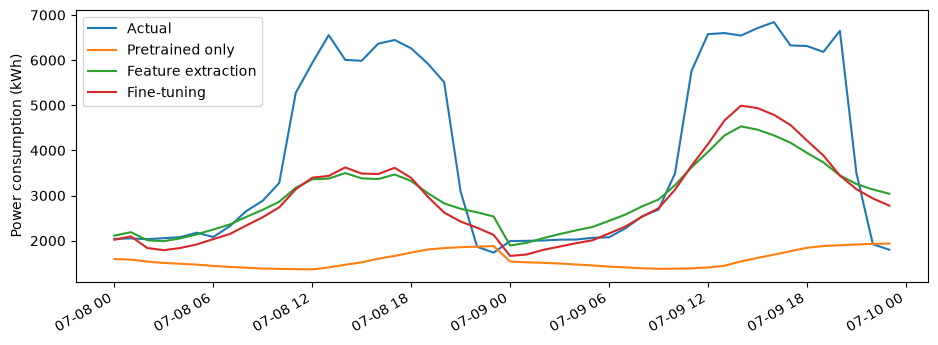

In [6]:
models = {"Pretrained only": pretrained,
          "Feature extraction": feature_model, "Fine-tuning": fine_model}
scores = target_scores(models)
print(scores.to_string(index=False))
# 각 모델의 표준화 예측값을 kWh로 되돌리세요.
pred_kwh = {name: predict_scaled(X_valid, params).ravel() * y_std + y_mean for name, params in models.items()}
# 처음 5행 표와 처음 48시간 그래프를 작성하세요.
first5 = pd.DataFrame({"time": target_valid["time"].iloc[:5].to_numpy(),
                       "Actual": target_valid[target].iloc[:5].to_numpy()})
for name, values in pred_kwh.items():
    first5[name] = values[:5]
print(first5.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, ax = plt.subplots(figsize=(11,4))
ax.plot(target_valid["time"].iloc[:48], target_valid[target].iloc[:48], label="Actual")
for name, values in pred_kwh.items():
    ax.plot(target_valid["time"].iloc[:48], values[:48], label=name)
ax.set_ylabel("Power consumption (kWh)")
ax.legend()
fig.autofmt_xdate()
plt.show()

#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. 세 모델의 대상 검증 MSE는 각각 얼마이며, 이번 실행에서는 어느 단계가 가장 낮나요?**

- 나의 답변: 대상 검증 MSE는 Pretrained only 7.568610, Feature extraction 2.346366, Fine-tuning 2.239531이다. 이번 실행에서는 Fine-tuning이 가장 낮다.

- 출력값 또는 코드 근거: `target_scores(models)`의 결과이며, 대상 학습 MSE는 각각 6.295834, 1.318850, 1.088650이다.

- 그렇게 판단한 이유: 세 모델을 같은 대상 검증 168행과 같은 표준화 기준으로 평가했으므로 이 범위 안에서 비교할 수 있다.

**Q2. Source에서 이미 학습한 모델인데도 바로 5번 건물에 적용하면 오차가 클 수 있는 이유는 무엇인가요? Fine-tuning은 언제나 더 좋은 결과를 만드나요?**

- 나의 답변: 건물마다 운영 방식과 사용 규모가 달라 Source에서 배운 관계와 출력이 5번 건물에 그대로 맞지 않을 수 있기 때문이다. Fine-tuning도 언제나 더 좋은 결과를 만드는 것은 아니며 데이터 양과 학습률에 따라 대상 학습에 지나치게 맞출 수도 있다.

- 출력값 또는 코드 근거: 처음 5행의 실제값은 약 2039.76~2078.64 kWh인데 Pretrained only는 1487.96~1591.42 kWh로 낮게 예측했다. 3행(02시)에서는 실제 2033.28에 대해 Feature extraction 2009.77이 Fine-tuning 1836.65보다 가깝다.

- 그렇게 판단한 이유: 전체 평균 MSE는 Fine-tuning이 낮아도 개별 시간에서는 다른 모델이 더 가까울 수 있다. 전체 표와 개별 값을 구분해야 한다.

**Q3. 이 표만으로 ‘사전학습을 쓰면 처음부터 학습하는 것보다 항상 좋다’고 결론 내릴 수 있나요? 최종 테스트 성능을 측정한 실험인가요?**

- 나의 답변: 결론 내릴 수 없다. 이 표에는 처음부터 학습한 모델이 없고 한 건물·한 기간의 결과일 뿐이다. 또한 대상 검증 자료로 비교한 것이며 별도의 최종 테스트 성능을 측정한 실험이 아니다.

- 출력값 또는 코드 근거: 비교한 세 모델은 모두 `pretrained`에서 이어진 단계이고 Scratch 학습은 없다. 데이터는 Source, Target Train, Target Validation만 사용했다.

- 그렇게 판단한 이유: 비교하지 않은 대상에 대해 우열을 말할 수 없고, 다른 건물이나 기간에서는 결과가 달라질 수 있다.


---

## 기초 과제. 업데이트 범위만 바꾸어 확인하기


### 문제 3-1. 같은 출발점에서 동결 여부만 바꾸기

#### 문제 설명

실습의 `feature_model`을 같은 출발점으로 두고 두 가지 추가 학습을 비교합니다. 이미 계산한 Fine-tuning 결과는 재사용할 수 있습니다. 핵심은 파라미터 고정 여부와 결과를 읽는 것입니다.

| 조건 | 시작 모델 | 추가 epoch | 학습률 | train_backbone |
|---|---|---:|---:|---|
| Frozen continuation | feature_model | 100 | 0.003 | False |
| Fine-tuning | feature_model | 100 | 0.003 | True |

#### 요구사항

1. 위의 Frozen continuation 조건으로 `frozen_more, frozen_history`를 만드세요.
2. `parameter_changes(feature_model, frozen_more)`로 은닉층이 고정되었는지 확인하세요.
3. `target_scores()`로 `frozen_more`와 실습에서 계산한 `fine_model`의 대상 손실을 나란히 출력하세요.
4. 업데이트 대상 숫자 개수와 실제 검증 결과를 근거로 아래 질문에 답하세요.

#### 작성 도움말

학습 함수에 `train_backbone=False`를 전달합니다. `feature_model`을 복사해서 학습하는 함수이므로 두 비교 조건은 같은 출발점을 유지합니다. `frozen_more`에서 다시 미세조정하면 시작점이 달라지므로 이번 비교와 다릅니다.

#### 해석 질문

**Q1.** 두 조건에서 같게 유지한 것과 다르게 설정한 것은 무엇인가요? 각각 몇 개의 파라미터를 업데이트하나요?

**Q2.** Frozen continuation의 W1·b1은 바뀌었나요? 출력층의 업데이트가 있었는데도 여전히 특징 추출부가 고정된 방식인 이유는 무엇인가요?

**Q3.** 두 조건의 검증 손실 중 어느 것이 낮나요? 결과와 한계를 포함하여 2~3문장으로 설명하세요.

#### 제출 결과

고정 여부 확인 표, 두 조건의 손실 비교 표, Q1~Q3 답변.


In [7]:
frozen_more, frozen_history = train_model(feature_model, X_train, y_train,
    lr=0.003, epochs=100, train_backbone=False)
frozen_changes = parameter_changes(feature_model, frozen_more)
homework_scores = target_scores({"Frozen continuation": frozen_more, "Fine-tuning": fine_model})
# 표를 출력하고 업데이트 범위와 검증 결과를 해석하세요.
print(frozen_changes.to_string(index=False))
print(homework_scores.to_string(index=False))
print("업데이트 개수 Frozen / Fine:", frozen_more["W2"].size + frozen_more["b2"].size,
      "/", sum(value.size for value in fine_model.values()))

parameter  count  max_abs_change
       W1     48        0.000000
       b1      8        0.000000
       W2      8        0.037881
       b2      1        0.003479
              model  target_train_mse  target_valid_mse
Frozen continuation          1.305568          2.339512
        Fine-tuning          1.088650          2.239531
업데이트 개수 Frozen / Fine: 9 / 65


#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. 두 조건에서 같게 유지한 것과 다르게 설정한 것은 무엇인가요? 각각 몇 개의 파라미터를 업데이트하나요?**

- 나의 답변: 시작 모델 `feature_model`, 추가 epoch 100, 학습률 0.003, 데이터를 같게 유지했고 `train_backbone`만 False와 True로 달리했다. Frozen continuation은 9개, Fine-tuning은 65개를 업데이트한다.

- 출력값 또는 코드 근거: `train_model(feature_model, X_train, y_train, lr=0.003, epochs=100, train_backbone=...)`이고 출력은 `업데이트 개수 Frozen / Fine: 9 / 65`다.

- 그렇게 판단한 이유: 조건을 하나만 다르게 해야 결과 차이를 은닉층 조정 여부와 연결해 읽을 수 있다.

**Q2. Frozen continuation의 W1·b1은 바뀌었나요? 출력층의 업데이트가 있었는데도 여전히 특징 추출부가 고정된 방식인 이유는 무엇인가요?**

- 나의 답변: W1·b1은 바뀌지 않았다. 업데이트가 출력층 W2·b2에서만 일어났으므로, 출력층이 바뀌었어도 특징 추출부는 여전히 고정된 방식이다.

- 출력값 또는 코드 근거: `frozen_changes`의 최대 변화가 W1 0, b1 0, W2 0.037881, b2 0.003479다.

- 그렇게 판단한 이유: 동결은 특징 추출부의 값을 바꾸지 않는다는 뜻이지 모델 전체의 학습을 멈춘다는 뜻이 아니다.

**Q3. 두 조건의 검증 손실 중 어느 것이 낮나요? 결과와 한계를 포함하여 2~3문장으로 설명하세요.**

- 나의 답변: 검증 손실은 Fine-tuning 2.239531이 Frozen continuation 2.339512보다 약 0.099981 낮다. 이번 건물과 기간에서는 은닉층까지 조정한 쪽이 더 나았지만, 한 번의 고정된 설정으로 얻은 결과이고 검증 자료로 비교한 값이라 항상 그렇다고 일반화할 수 없다.

- 출력값 또는 코드 근거: `homework_scores`: Frozen continuation 학습 1.305568·검증 2.339512, Fine-tuning 학습 1.088650·검증 2.239531.

- 그렇게 판단한 이유: 같은 출발점·학습률·횟수에서 다른 것은 동결 여부뿐이므로 이번 결과 차이는 그 차이와 연결된다. 다만 초기값이나 대상 건물을 바꾼 반복 실험은 하지 않았다.


---

## 실습 마무리

실습 결과를 보고 아래 여섯 질문에 자신의 말로 답하세요. 단순히 체크하는 항목이 아니라 **개념·코드·결과를 연결해 쓰는 복습 문제**입니다. 새 코드를 만들거나 심화 내용을 조사할 필요는 없습니다. 답을 먼저 작성한 뒤 정답 파일의 상세 해설과 비교하세요.

### 마무리 1. 사전학습과 전달

`initial`, `pretrained`, `feature_model`, `fine_model`의 순서를 적고 각 단계에서 사용한 데이터와 업데이트한 부분을 설명하세요. Source에서 Target으로 전달한 것은 무엇인가요?

- 나의 답변: `initial` → `pretrained`(Source로 65개 모두 학습) → `feature_model`(Target Train으로 새 출력층 9개만 학습) → `fine_model`(Target Train으로 65개 모두 작은 폭으로 학습) 순서다. Source에서 Target으로 전달한 것은 학습된 은닉층의 가중치·편향이다.

- 코드·수치 근거: Source 손실 0.943519→0.520916, Feature 단계 손실 5.714717→1.318850, Fine 단계 후 학습 MSE 1.088650. Source 행과 정답은 전달하지 않았다.

- 헷갈렸던 점과 고친 설명: `feature_start`를 복사할 때 W2·b2도 복사되지만 곧바로 새 값으로 바꾸므로, 실제로 재사용한 것은 W1·b1이라는 점을 구분해 정리했다.


### 마무리 2. 특징과 파라미터

X_train의 모양이 (168,6)일 때 H와 최종 예측의 모양을 쓰세요. W1·b1·W2·b2의 숫자 개수와 전체 개수를 계산하고, H의 8개 특징이 무엇을 뜻하는지 설명하세요.

- 나의 답변: H는 (168, 8), 최종 예측은 (168, 1)이다. W1 48개, b1 8개, W2 8개, b2 1개로 전체 65개다. H의 8개 특징은 입력 6개를 조합해 은닉 뉴런 8개가 만든 중간 값이다.

- 코드·수치 근거: 6×8 = 48, 8, 8×1 = 8, 1을 더해 65다. `H_train.shape` = (168, 8)이다.

- 헷갈렸던 점과 고친 설명: 168은 샘플 수이고 파라미터 수가 아니다. 모든 행이 같은 W1·b1을 공유하므로 168을 곱하지 않는다.


### 마무리 3. 동결의 의미

Feature Extraction에서 W1 동일=True, b1 동일=True, H 동일=True인데도 예측값이 달라질 수 있는 이유를 설명하세요. 동결하면 은닉층을 생략한다는 설명이 맞는지도 답하세요.

- 나의 답변: H가 같아도 출력층 W2·b2가 학습되어 `H @ W2 + b2`가 달라지기 때문이다. 동결하면 은닉층을 생략한다는 설명은 틀리다. 은닉층은 계산하되 업데이트만 하지 않는다.

- 코드·수치 근거: W1 동일 True, b1 동일 True, H 동일 True이고 W2의 최대 변화 2.087094, b2 0.394808, 학습 전후 첫 행 예측은 달랐다.

- 헷갈렸던 점과 고친 설명: `np.array_equal`의 True는 설정이 아니라 비교 결과이며, 동결된 값끼리 비교하면 True가 정상이다.


### 마무리 4. 미세조정의 출발점

Fine-tuning에 feature_model을 사용하는 이유와 작은 학습률을 쓰는 이유를 설명하세요. 학습률 0.003과 train_backbone=False는 같은 의미인가요?

- 나의 답변: `feature_model`은 대상 건물에 맞춘 출력층과 사전학습 은닉층을 이미 갖추고 있어 좋은 출발점이기 때문이다. 작은 학습률은 학습된 값을 크게 흔들지 않기 위해 쓴다. 학습률 0.003과 `train_backbone=False`는 다른 의미다. 전자는 변경 크기이고 후자는 은닉층 업데이트 여부다.

- 코드·수치 근거: Fine-tuning은 `lr=0.003, train_backbone=True`로 W1이 최대 0.125444 바뀌었고, Frozen은 `lr=0.003, train_backbone=False`로 W1 변화가 0이었다.

- 헷갈렸던 점과 고친 설명: 학습률이 작으면 은닉층도 동결된다고 혼동하기 쉽지만, 같은 0.003에서 W1 변화가 다르게 나타나므로 서로 다른 설정이다.


### 마무리 5. 성능과 단위

세 단계의 대상 검증 MSE를 비교하여 이번 결과를 설명하세요. 그 MSE를 평균 kWh 오차나 모든 시간에서의 우열로 해석해도 되는지, 별도 최종 테스트 성능인지도 답하세요.

- 나의 답변: 대상 검증 MSE는 Pretrained only 7.568610, Feature extraction 2.346366, Fine-tuning 2.239531로 이번 결과에서는 Fine-tuning이 가장 낮다. 이 MSE는 Source 기준 표준화 값이므로 평균 kWh 오차가 아니고, 모든 시간에서 우열을 뜻하지도 않으며, 별도의 최종 테스트 성능도 아니다.

- 코드·수치 근거: 02시 실제 2033.28에 Feature extraction 2009.77, Fine-tuning 1836.65로 개별 시간에서는 순위가 뒤바뀌기도 한다.

- 헷갈렸던 점과 고친 설명: MSE를 kWh로 바로 읽기 쉽지만, 예측값을 `× y_std + y_mean`으로 되돌린 것이 kWh이고 MSE는 표준화 척도의 제곱 오차 평균이다.


### 마무리 6. 비교 조건과 핵심 정리

과제에서 같게 유지한 조건과 바꾼 조건을 설명하고, Pretrained Model·Feature Extraction·Fine-tuning을 각각 한 문장으로 정리하세요.

- 나의 답변: 과제는 출발 모델, 추가 100 epoch, 학습률 0.003, 대상 데이터를 같게 두고 은닉층 고정 여부만 바꿨다. Pretrained Model은 Source로 학습을 마친 모델이고, Feature Extraction은 사전학습 은닉층을 고정한 채 새 출력층만 학습하는 방식이며, Fine-tuning은 학습된 값에서 출발해 은닉층까지 대상 데이터로 추가 조정하는 방식이다.

- 코드·수치 근거: Frozen 9개·검증 2.339512, Fine-tuning 65개·검증 2.239531.

- 헷갈렸던 점과 고친 설명: Feature Extraction과 Fine-tuning을 무관한 주제로 외우기 쉽지만, 어떤 값을 이어받아 무엇을 고정·조정하는가로 보면 한 흐름의 단계다.


## 제출 전 확인

- 실습 2개와 기초 과제 1개의 출력 및 해석 질문 18개를 작성했나요?
- 실습 마무리 여섯 질문에 자신의 설명과 근거를 적었나요?
- W1·b1 고정과 H 계산을 구분하고, 56개·9개·65개를 계산할 수 있나요?
- 각 변화 표의 비교 전·후 모델을 정확히 확인했나요?
- MSE와 kWh 예측값, 전체 평균과 개별 시간 결과를 구분했나요?
- 이번 건물·기간의 결과를 모든 경우에 일반화하지 않았나요?

CSV 두 개와 노트북을 같은 폴더에 두고 처음부터 순서대로 실행합니다. 정답 파일의 저장된 출력은 제공 데이터로 실제 실행한 결과입니다. 환경에 따른 마지막 소수점 차이보다 같은 입력·비교 조건·계산 의미를 확인하세요.
